# Metrics vs frequency – all scans of `EDD_2023-03-11T14_58_01`

x = [fc, B99, FWHM, B10, B20, B30, RBW, A, S] vs frequency

This notebook reads the combined table made in `data_combination.ipynb` (one row per peak group per scan) and shows how each metric changes with frequency. Each peak group is assigned to the frequency allocation that contains its reference frequency, using the same bands as `SKAMPI_RFI_PIPELINE/rfi_analysis_workflow.ipynb`.

## Step 1 – Imports and loading the combined data

`metrics_per_peak_combined_EDD_2023-03-11T14_58_01.csv` is in the same folder as this notebook. Every row is one peak group of one scan, and every metric is the **median over the time bins** in which the peak was detected.

We also add `f_ref_GHz`: the reference frequency is stored in kHz, but the allocations are defined in GHz.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = Path.cwd()
OBS_ID = BASE_DIR.name   # 'EDD_2023-03-11T14_58_01'

metrics_all = pd.read_csv(BASE_DIR / f"metrics_per_peak_combined_{OBS_ID}.csv")
metrics_all["f_ref_GHz"] = metrics_all["f_ref_kHz"] / 1e6

print(metrics_all.shape)
metrics_all[["scan_id", "peak_group", "f_ref_GHz", "band", "detection_level", "n_bins"]].head()

(302, 29)


,scan_id,peak_group,f_ref_GHz,band,detection_level,n_bins
0,scan_000_P1_ND0,0,1.819628,Cellular GSM Downlink,high,105
1,scan_000_P1_ND0,1,1.846865,Cellular GSM Downlink,low,1
2,scan_000_P1_ND0,2,1.873568,Cellular GSM Downlink,high,9
3,scan_000_P1_ND0,3,1.875917,Cellular GSM Downlink,high,5
4,scan_000_P1_ND0,4,1.877920,Cellular GSM Downlink,low,1


## Step 2 – Frequency allocations

These are the same dictionaries as in `SKAMPI_RFI_PIPELINE/rfi_analysis_workflow.ipynb`:

* `RFI_BANDS` – the known service allocations in the S-band.
* `TRANSITION_BANDS` – the small gaps between them.

Both are merged into `ALL_BANDS` and sorted by their lower edge, so later plots list the bands in frequency order.

In [2]:
# Frequency allocations (GHz), as in SKAMPI_RFI_PIPELINE/rfi_analysis_workflow.ipynb
RFI_BANDS = {
    "Cellular GSM Uplink": (1.71, 1.785),
    "Cellular GSM Downlink": (1.805, 1.88),
    "DECT Phones": (1.88, 1.90),
    "UMTS Uplink": (1.92, 1.98),
    "UMTS Downlink": (2.11, 2.17),
    "Mobile Satellite": (2.00, 2.20),
    "Space Research / EESS": (2.20, 2.29),
    "IMT 2300 (4G/5G)": (2.30, 2.40),
    "Wi-Fi / Bluetooth (ISM)": (2.40, 2.483),
    "LTE / 5G (2600 band)": (2.50, 2.69),
    "Air Traffic Radar": (2.70, 2.90),
    "Weather Radar": (2.70, 3.00),
    "Microwave Backhaul": (3.00, 3.30),
    "5G NR (n78)": (3.30, 3.60),
}
TRANSITION_BANDS = {
    "Gap: GSM DL to GSM UL": (1.785, 1.805),
    "Gap: DECT to UMTS UL": (1.90, 1.92),
    "Gap: UMTS UL to MSS": (1.98, 2.00),
    "Gap: EESS to IMT-2300": (2.29, 2.30),
    "Gap: ISM to LTE 2600": (2.483, 2.50),
    "Gap: LTE 2600 to Radar": (2.69, 2.70),
}
ALL_BANDS = dict(sorted({**RFI_BANDS, **TRANSITION_BANDS}.items(), key=lambda kv: kv[1][0]))

## Step 3 – Assign each peak group to an allocation

A peak belongs to the allocation where `lo <= f_ref < hi`. Some allocations overlap:

* UMTS Downlink (2.11–2.17 GHz) lies inside Mobile Satellite (2.00–2.20 GHz).
* Air Traffic Radar (2.70–2.90 GHz) lies inside Weather Radar (2.70–3.00 GHz).

In these cases the peak goes to the **narrowest** allocation, because it is the more specific one. This is the same rule the pipeline used in `peak_analyses_t6.ipynb`. Peaks outside every allocation are labelled `Unallocated`.

We recompute the band here instead of trusting the `band` column, then check that both agree.

In [3]:
def assign_band(f_ghz):
    """Narrowest allocation containing f (so overlapping bands resolve to the most specific one)."""
    hits = [(hi - lo, name) for name, (lo, hi) in ALL_BANDS.items() if lo <= f_ghz < hi]
    return min(hits)[1] if hits else "Unallocated"

metrics_all["allocation"] = metrics_all["f_ref_GHz"].map(assign_band)

mismatch = metrics_all["allocation"] != metrics_all["band"]
print(f"peaks whose allocation differs from the stored band: {mismatch.sum()}")

# allocations in frequency order, only those with detections
BAND_ORDER = [b for b in [*ALL_BANDS, "Unallocated"] if b in set(metrics_all["allocation"])]
# peak counts per allocation, split by scan and detection level (high / low)
pd.crosstab(metrics_all["allocation"], [metrics_all["scan_id"], metrics_all["detection_level"]],
            margins=True).reindex([*BAND_ORDER, "All"])

peaks whose allocation differs from the stored band: 0


scan_id                 scan_000_P1_ND0     scan_001_P0_ND0       \
detection_level                    high low            high  low   
allocation                                                         
Gap: GSM DL to GSM UL                 0   0               0    1   
Cellular GSM Downlink                 3   2               1    1   
DECT Phones                           0   2               0    0   
UMTS Uplink                           0   0               0    0   
Mobile Satellite                      4   4               5    7   
UMTS Downlink                         3   0               0    3   
Space Research / EESS                 0  11               2   14   
Gap: EESS to IMT-2300                 0   2               0    3   
IMT 2300 (4G/5G)                      1  14               1   21   
Wi-Fi / Bluetooth (ISM)               0  17               1   21   
Gap: ISM to LTE 2600                  1   3               1    2   
LTE / 5G (2600 band)                  0   8               1   19   
Gap: LTE 2600 to Radar                0   0               0    2   
Air Traffic Radar                     0   5               3   31   
All                                  12  68              15  125   

scan_id                 scan_001_P1_ND0      All  
detection_level                    high low       
allocation                                        
Gap: GSM DL to GSM UL                 0   0    1  
Cellular GSM Downlink                 1   4   12  
DECT Phones                           0   1    3  
UMTS Uplink                           0   1    1  
Mobile Satellite                      4   1   25  
UMTS Downlink                         2   2   10  
Space Research / EESS                 0   9   36  
Gap: EESS to IMT-2300                 0   2    7  
IMT 2300 (4G/5G)                      1  17   55  
Wi-Fi / Bluetooth (ISM)               0  15   54  
Gap: ISM to LTE 2600                  1   3   11  
LTE / 5G (2600 band)                  0  10   38  
Gap: LTE 2600 to Radar                0   0    2  
Air Traffic Radar                     0   8   47  
All                                   9  73  302

## Step 4 – Which metrics are plotted

The requested list is `[fc, B99, FWHM, B10, B20, B30, RBW, A, S]`. Because the table holds one row per peak, the centre frequency `fc` is almost the same as the x-axis (`f_ref`), so plotting it against frequency would give a straight line. Instead we use **`fc_std`**: how much `fc` drifts in time (kHz). This is the column the pipeline stores for `fc`.

* `fc_std`, `B99`, `FWHM`, `B10`, `B20`, `B30`: in kHz
* `RBW` = B99 / FWHM: a ratio, with no unit
* `A`: amplitude, in counts
* `S`: skewness, with no unit

Metrics spanning several orders of magnitude are drawn on a log y-axis. `RBW` and `S` stay linear, because `S` can be negative.

`fc_std` is missing for the peaks seen in a single time bin (`n_bins == 1`), so those peaks do not appear in that one panel.

In [4]:
METRICS = ["fc_std", "B99", "FWHM", "B10", "B20", "B30", "RBW", "A", "S"]
LOG_METRICS = {"fc_std", "B99", "FWHM", "B10", "B20", "B30", "A"}
UNITS = {m: "kHz" for m in ["fc_std", "B99", "FWHM", "B10", "B20", "B30"]} | {"RBW": "", "A": "counts", "S": ""}

def axis_label(metric):
    return f"{metric} [{UNITS[metric]}]" if UNITS[metric] else metric

# one fixed colour per scan; marker fill shows the detection level
SCAN_COLOURS = dict(zip(sorted(metrics_all["scan_id"].unique()), ["#2a78d6", "#eb6834", "#1baf7a"]))
SCAN_LABELS = (metrics_all.drop_duplicates("scan_id")
               .set_index("scan_id")
               .apply(lambda r: f"{r.name} ({r.scan_type}, {r.polarization})", axis=1))

## Step 5 – Metrics vs frequency (all peaks)

One panel per metric, one point per peak group:

* **x-axis:** reference frequency of the peak (GHz).
* **colour:** the scan the peak came from.
* **filled / hollow marker:** high- or low-level detection.
* **grey shading:** the allocations that contain detections, alternating light and dark grey so neighbouring bands can be told apart.

Comparing colours at the same frequency shows whether the same emitter looks different between scans or polarisations.

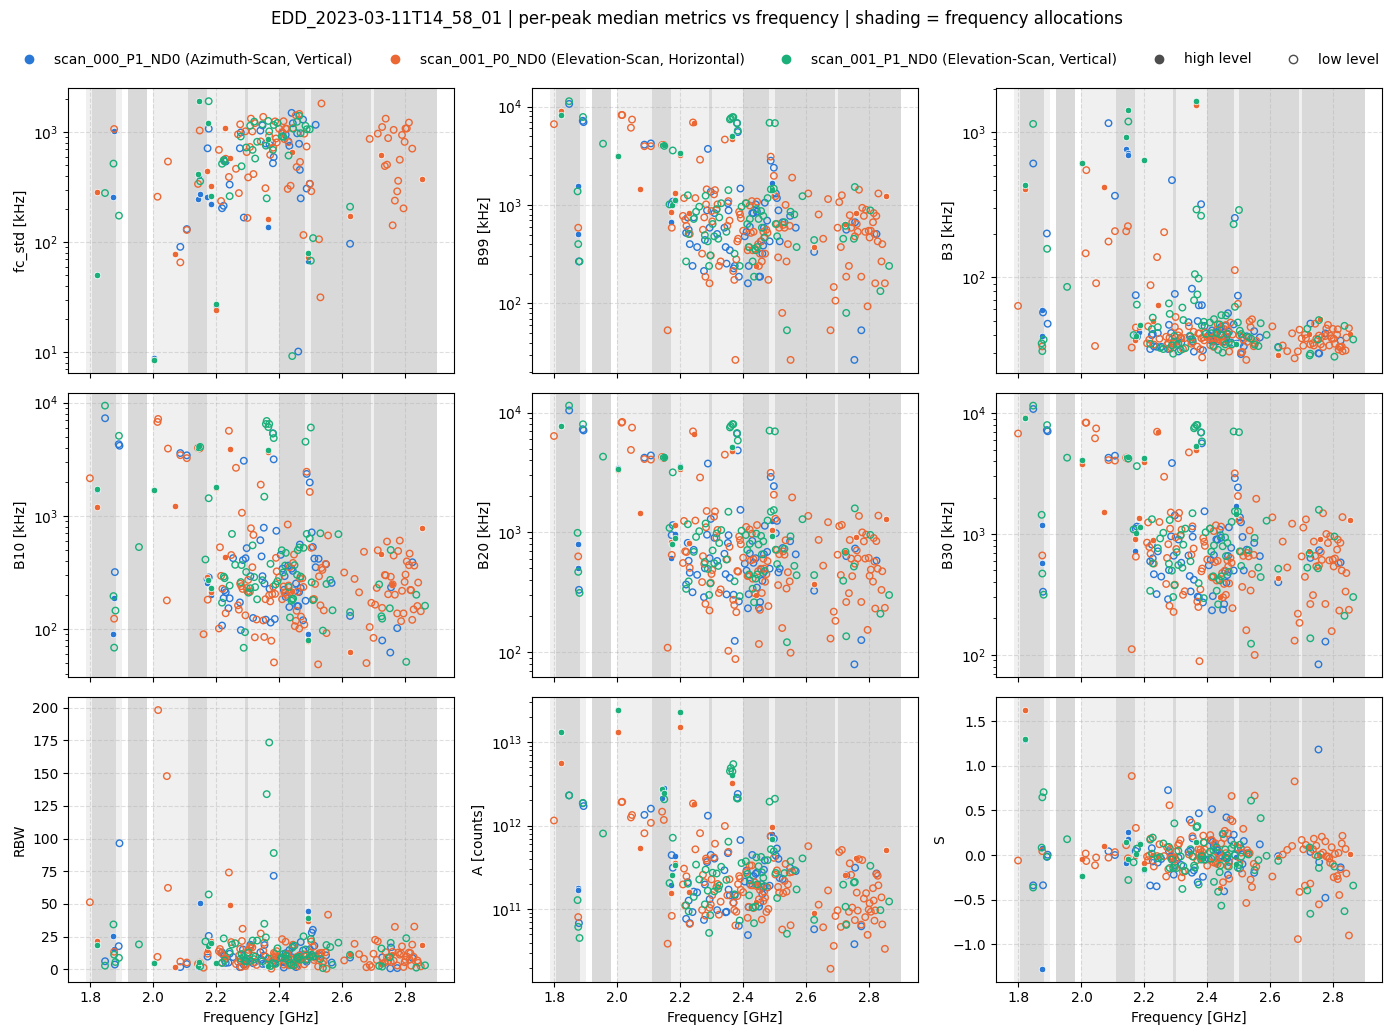

In [5]:
def shade_bands(ax):
    """Alternate grey shading of the allocations that contain detections."""
    for k, name in enumerate(b for b in BAND_ORDER if b != "Unallocated"):
        lo, hi = ALL_BANDS[name]
        ax.axvspan(lo, hi, color="0.85" if k % 2 else "0.94", zorder=0, lw=0)

fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True)
for ax, metric in zip(axes.flat, METRICS):
    shade_bands(ax)
    for scan_id, colour in SCAN_COLOURS.items():
        d = metrics_all[metrics_all["scan_id"] == scan_id]
        high = d["detection_level"] == "high"
        ax.scatter(d.loc[high, "f_ref_GHz"], d.loc[high, metric], s=22,
                   color=colour, edgecolor="white", linewidth=0.5, zorder=3)
        ax.scatter(d.loc[~high, "f_ref_GHz"], d.loc[~high, metric], s=22,
                   facecolor="none", edgecolor=colour, linewidth=1, zorder=3)
    if metric in LOG_METRICS:
        ax.set_yscale("log")
    ax.set_ylabel(axis_label(metric))
    ax.grid(True, ls="--", alpha=0.4)
for ax in axes[-1]:
    ax.set_xlabel("Frequency [GHz]")

# legend: colour = scan, fill = detection level
handles = [plt.Line2D([], [], ls="", marker="o", color=c, label=SCAN_LABELS[s]) for s, c in SCAN_COLOURS.items()]
handles += [plt.Line2D([], [], ls="", marker="o", color="0.3", label="high level"),
            plt.Line2D([], [], ls="", marker="o", mfc="none", color="0.3", label="low level")]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"{OBS_ID} | per-peak median metrics vs frequency | shading = frequency allocations", y=1.03)
fig.tight_layout()

## Step 6 – Distribution of each metric per allocation

The scatter plot shows individual peaks. To compare **allocations**, we group the peaks by allocation and draw a box plot per band, with all scans pooled:

* The box covers the 25–75 % range and the line inside it is the median.
* The whiskers reach 1.5 × IQR.
* The coloured points on top are the individual peaks, coloured by scan, with a small horizontal jitter so they don't overlap.

Bands are ordered by frequency, and the count under each name is the number of peaks in that band.

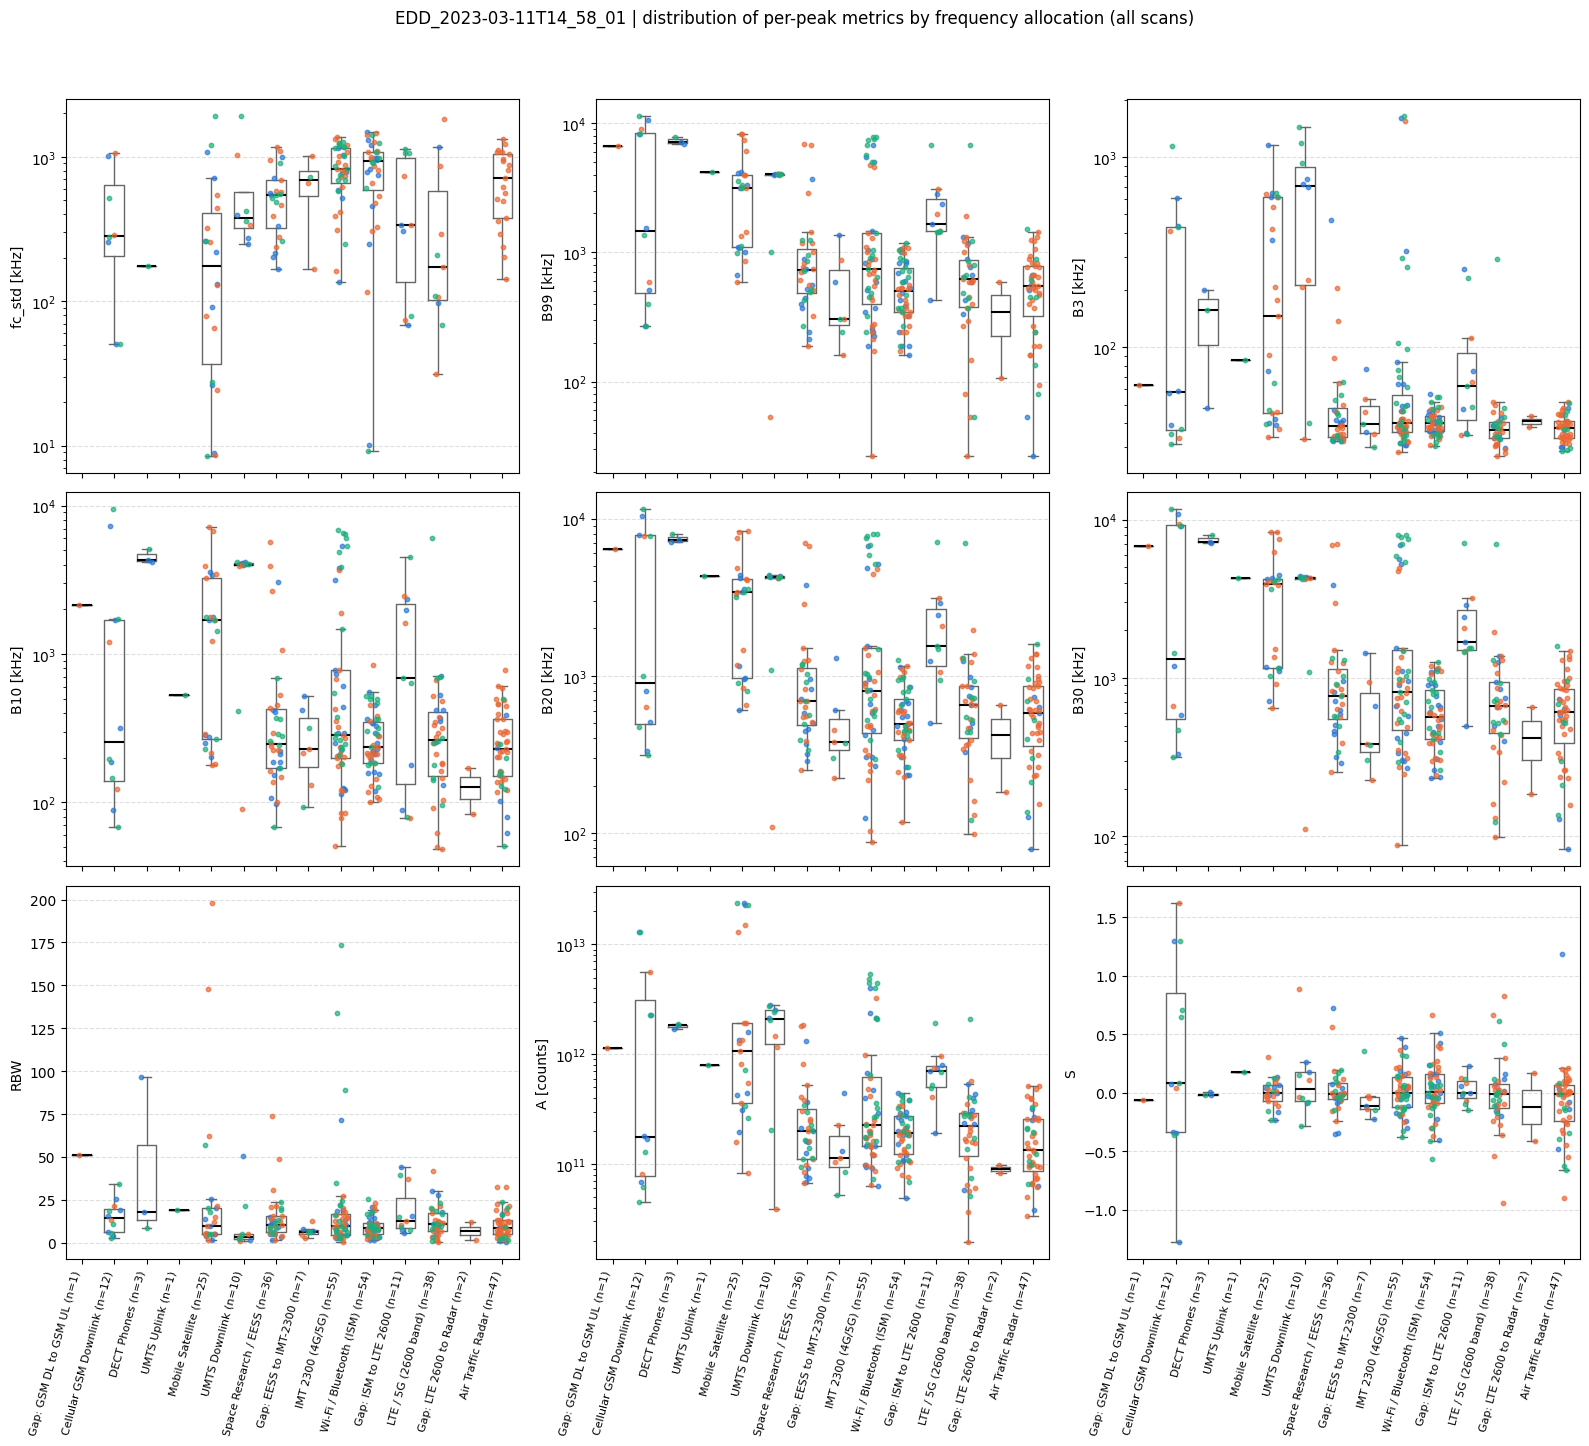

In [6]:
rng = np.random.default_rng(0)
n_per_band = metrics_all["allocation"].value_counts()
tick_labels = [f"{b} (n={n_per_band[b]})" for b in BAND_ORDER]

fig, axes = plt.subplots(3, 3, figsize=(16, 14), sharex=True)
for ax, metric in zip(axes.flat, METRICS):
    groups = [metrics_all.loc[metrics_all["allocation"] == b, metric].dropna() for b in BAND_ORDER]
    ax.boxplot(groups, positions=range(len(BAND_ORDER)), widths=0.6, showfliers=False,
               medianprops=dict(color="k", lw=1.5), boxprops=dict(color="0.4"),
               whiskerprops=dict(color="0.4"), capprops=dict(color="0.4"))
    for scan_id, colour in SCAN_COLOURS.items():
        d = metrics_all[metrics_all["scan_id"] == scan_id]
        x = d["allocation"].map(BAND_ORDER.index) + rng.uniform(-0.2, 0.2, len(d))
        ax.scatter(x, d[metric], s=10, color=colour, alpha=0.7, zorder=3)
    if metric in LOG_METRICS:
        ax.set_yscale("log")
    ax.set_ylabel(axis_label(metric))
    ax.grid(True, axis="y", ls="--", alpha=0.4)
for ax in axes[-1]:
    ax.set_xticks(range(len(BAND_ORDER)), tick_labels, rotation=75, ha="right", fontsize=8)



# # legend: colour = scan, fill = detection level
# handles = [plt.Line2D([], [], ls="", marker="o", color=c, label=SCAN_LABELS[s]) for s, c in SCAN_COLOURS.items()]
# handles += [plt.Line2D([], [], ls="", marker="o", color="0.3", label="high level"),
#             plt.Line2D([], [], ls="", marker="o", mfc="none", color="0.3", label="low level")]
# fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.0))


fig.suptitle(f"{OBS_ID} | distribution of per-peak metrics by frequency allocation (all scans)", y=1.03)
fig.tight_layout()

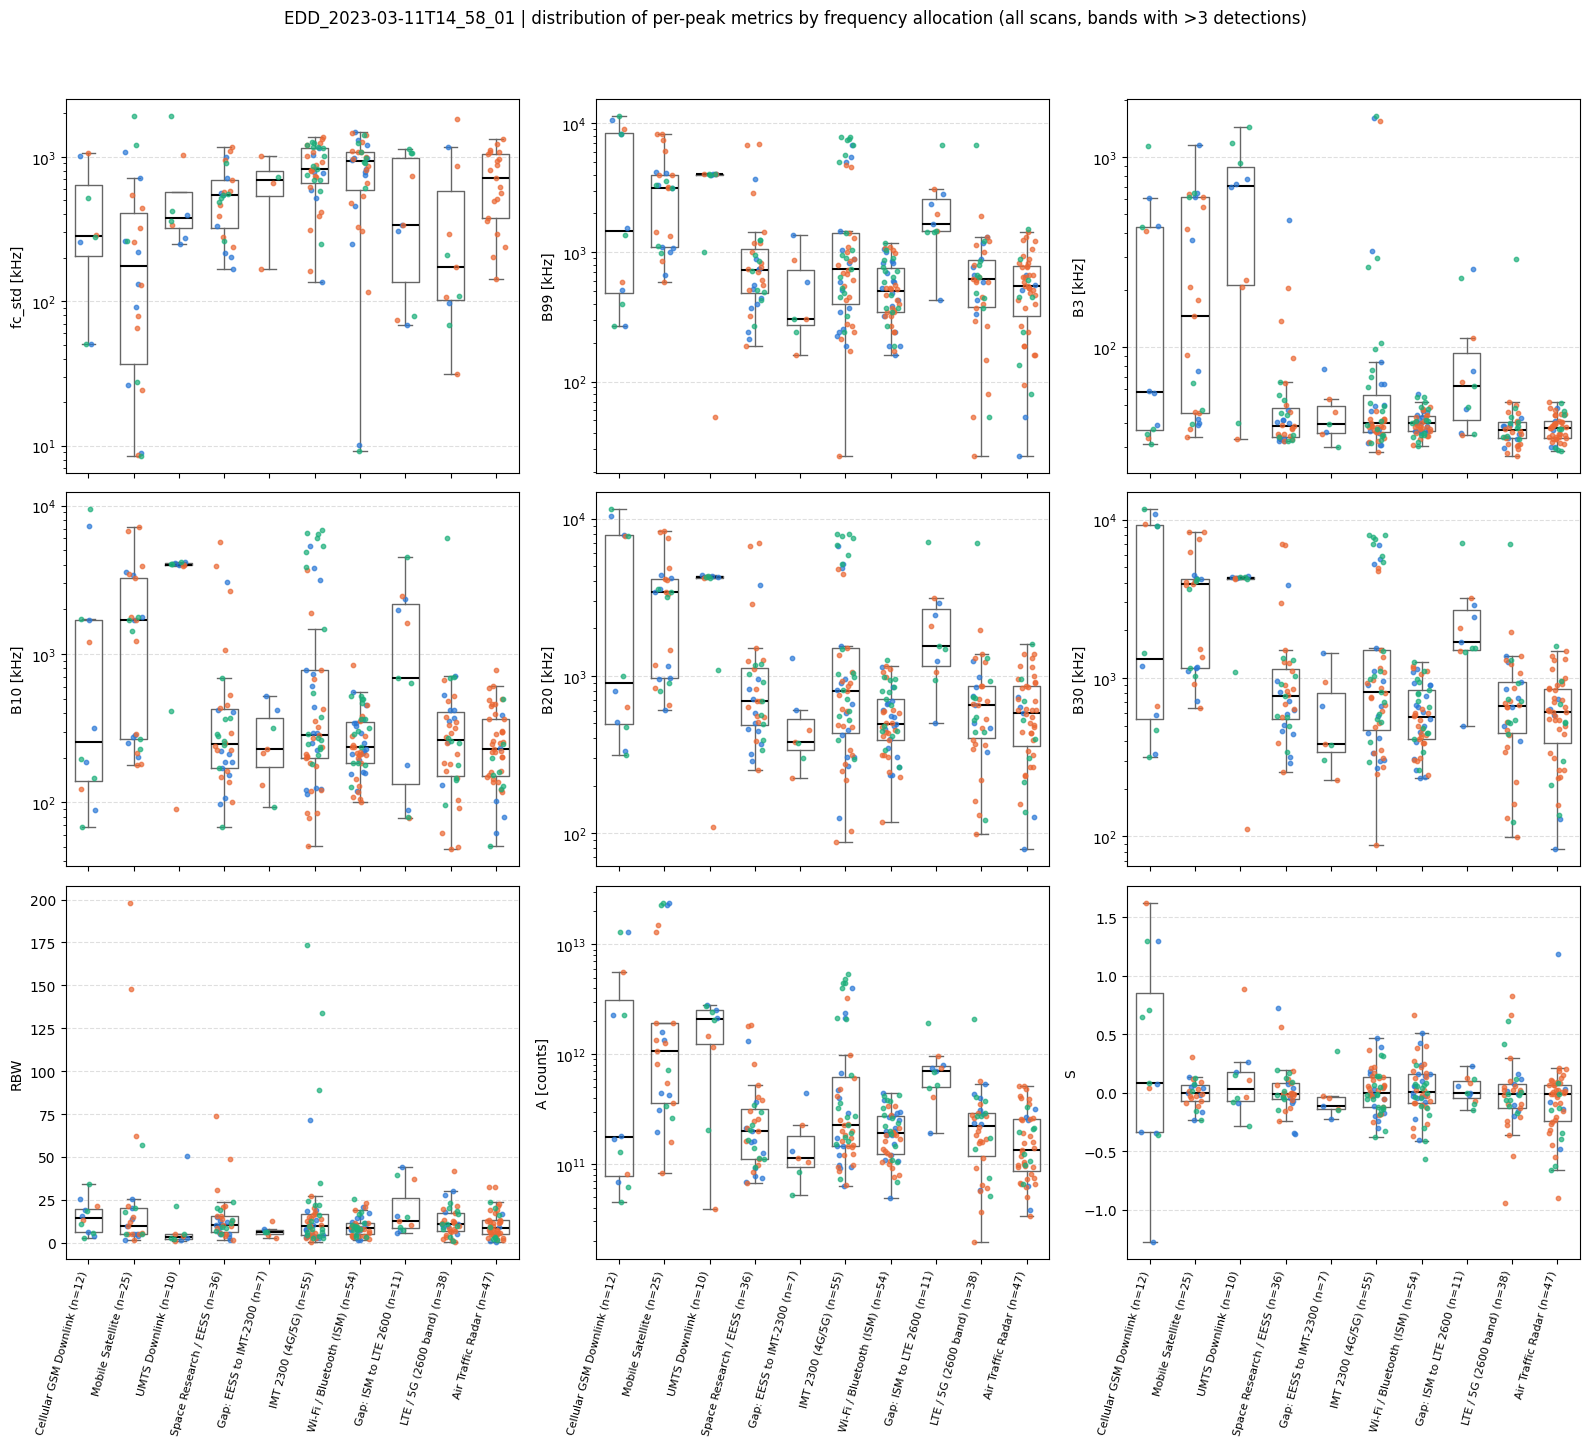

In [7]:
# plot the distribution of per-peak metrics, split by frequency allocation
# only frequency allocations that contain more than 3 detections are plotted
MIN_DETECTIONS = 3

rng = np.random.default_rng(0)
n_per_band = metrics_all["allocation"].value_counts()
bands = [b for b in BAND_ORDER if n_per_band.get(b, 0) > MIN_DETECTIONS]
metrics_sel = metrics_all[metrics_all["allocation"].isin(bands)]
tick_labels = [f"{b} (n={n_per_band[b]})" for b in bands]

fig, axes = plt.subplots(3, 3, figsize=(16, 14), sharex=True)
for ax, metric in zip(axes.flat, METRICS):
    groups = [metrics_sel.loc[metrics_sel["allocation"] == b, metric].dropna() for b in bands]
    ax.boxplot(groups, positions=range(len(bands)), widths=0.6, showfliers=False,
               medianprops=dict(color="k", lw=1.5), boxprops=dict(color="0.4"),
               whiskerprops=dict(color="0.4"), capprops=dict(color="0.4"))
    for scan_id, colour in SCAN_COLOURS.items():
        d = metrics_sel[metrics_sel["scan_id"] == scan_id]
        x = d["allocation"].map(bands.index) + rng.uniform(-0.2, 0.2, len(d))
        ax.scatter(x, d[metric], s=10, color=colour, alpha=0.7, zorder=3)
    if metric in LOG_METRICS:
        ax.set_yscale("log")
    ax.set_ylabel(axis_label(metric))
    ax.grid(True, axis="y", ls="--", alpha=0.4)
for ax in axes.flat[len(METRICS):]:   # hide unused panels if METRICS < 9
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xticks(range(len(bands)), tick_labels, rotation=75, ha="right", fontsize=8)

fig.suptitle(f"{OBS_ID} | distribution of per-peak metrics by frequency allocation "
             f"(all scans, bands with >{MIN_DETECTIONS} detections)", y=1.03)
fig.tight_layout()


## Step 7 – Summary table per allocation and scan

The median of each metric per allocation and scan, plus the number of peaks. Use this table to read off the values behind the plots, or to compare the same band between scans (for example `scan_001_P0_ND0` and `scan_001_P1_ND0`, which are the two polarisations of the same scan).

In [8]:
band_summary = (metrics_all
                .groupby(["allocation", "scan_id"])
                .agg(n_peaks=("peak_uid", "size"), **{m: (m, "median") for m in METRICS})
                .reindex(BAND_ORDER, level="allocation"))
band_summary

n_peaks       fc_std          B99  \
allocation              scan_id                                              
Gap: GSM DL to GSM UL   scan_001_P0_ND0        1          NaN  6622.314453   
Cellular GSM Downlink   scan_000_P1_ND0        5   258.051115  1548.767090   
                        scan_001_P0_ND0        2   676.388073  4799.842834   
                        scan_001_P1_ND0        5   279.814439  1375.198364   
DECT Phones             scan_000_P1_ND0        2          NaN  7049.560547   
                        scan_001_P1_ND0        1   174.366296  7823.944092   
UMTS Uplink             scan_001_P1_ND0        1          NaN  4192.352295   
Mobile Satellite        scan_000_P1_ND0        8   176.026267  2136.230469   
                        scan_001_P0_ND0       12   129.267095  3578.186035   
                        scan_001_P1_ND0        5   262.411304  3150.939941   
UMTS Downlink           scan_000_P1_ND0        3   274.380113  4045.486450   
                        scan_001_P0_ND0        3   686.401221  4058.837891   
                        scan_001_P1_ND0        4   418.740555  4005.432129   
Space Research / EESS   scan_000_P1_ND0       11   437.540757   520.706177   
                        scan_001_P0_ND0       16   575.288534   801.086426   
                        scan_001_P1_ND0        9   529.116884   720.977783   
Gap: EESS to IMT-2300   scan_000_P1_ND0        2          NaN   974.655151   
                        scan_001_P0_ND0        3   658.745083   307.083130   
                        scan_001_P1_ND0        2   725.356957   273.704529   
IMT 2300 (4G/5G)        scan_000_P1_ND0       15   772.007425   587.463379   
                        scan_001_P0_ND0       22   814.925371   687.599182   
                        scan_001_P1_ND0       18   942.211296  1001.358032   
Wi-Fi / Bluetooth (ISM) scan_000_P1_ND0       17   886.632760   534.057617   
                        scan_001_P0_ND0       22   916.630455   413.894653   
                        scan_001_P1_ND0       15   946.325692   640.869141   
Gap: ISM to LTE 2600    scan_000_P1_ND0        4   307.239519  2022.743225   
                        scan_001_P0_ND0        3   338.361247  1976.013184   
                        scan_001_P1_ND0        4  1061.005956  1455.307007   
LTE / 5G (2600 band)    scan_000_P1_ND0        8   631.376154   720.977783   
                        scan_001_P0_ND0       20   231.116310   587.463379   
                        scan_001_P1_ND0       10   109.071993   654.220581   
Gap: LTE 2600 to Radar  scan_001_P0_ND0        2          NaN   347.137451   
Air Traffic Radar       scan_000_P1_ND0        5          NaN   507.354736   
                        scan_001_P0_ND0       34   708.473413   567.436218   
                        scan_001_P1_ND0        8          NaN   453.948975   

                                                  B3          B10  \
allocation              scan_id                                     
Gap: GSM DL to GSM UL   scan_001_P0_ND0    63.496405  2147.518940   
Cellular GSM Downlink   scan_000_P1_ND0    59.049512   317.816752   
                        scan_001_P0_ND0   221.390817   663.129076   
                        scan_001_P1_ND0    37.151036   195.040712   
DECT Phones             scan_000_P1_ND0   124.227516  4227.628409   
                        scan_001_P1_ND0   157.239311  5093.409181   
UMTS Uplink             scan_001_P1_ND0    85.900200   528.878728   
Mobile Satellite        scan_000_P1_ND0   220.291628   992.304639   
                        scan_001_P0_ND0   161.496273  1731.770202   
                        scan_001_P1_ND0    64.806030  1429.434984   
UMTS Downlink           scan_000_P1_ND0   718.609037  4074.007015   
                        scan_001_P0_ND0   207.814323  3936.582712   
                        scan_001_P1_ND0  1059.929720  4037.298689   
Space Research / EESS   scan_000_P1_ND0    39.881037   187.155632   
                        scan_001_P0_ND0    38.0158

In [11]:
band_summary.xs("scan_001_P0_ND0", level="scan_id")

,n_peaks,fc_std,B99,B3,B10,B20,B30,RBW,A,S
allocation,,,,,,,,,,
Gap: GSM DL to GSM UL,1,NaN,6622.314453,63.496405,2147.518940,6377.729844,6805.978043,51.277979,1.151675e+12,-0.061512
Cellular GSM Downlink,2,676.388073,4799.842834,221.390817,663.129076,4185.831304,5013.896794,17.463162,2.820839e+12,0.834707
Mobile Satellite,12,129.267095,3578.186035,161.496273,1731.770202,3728.192286,3996.431823,10.714234,1.166971e+12,-0.017397
UMTS Downlink,3,686.401221,4058.837891,207.814323,3936.582712,4182.751649,4217.266054,4.099486,1.170554e+12,0.110306
Space Research / EESS,16,575.288534,801.086426,38.015870,272.641412,758.392583,873.897019,13.070890,2.534706e+11,-0.008442
Gap: EESS to IMT-2300,3,658.745083,307.083130,45.409398,214.829248,379.745420,380.683660,4.242589,1.138257e+11,-0.045898
IMT 2300 (4G/5G),22,814.925371,687.599182,38.239233,208.432052,605.939865,755.593720,10.209480,1.774897e+11,0.049736
Wi-Fi / Bluetooth (ISM),22,916.630455,413.894653,38.201312,212.757200,461.384024,487.062054,7.888937,1.659626e+11,0.023797
Gap: ISM to LTE 2600,3,338.361247,1976.013184,65.621650,1624.309109,2064.676001,2066.032883,12.578267,7.522176e+11,0.081700


## Step 8 – Median and spread of each metric per service and scan

Does a service look the same in every scan? High- and low-level peaks come from different detection thresholds and can have very different shapes, so they are kept apart. For each allocation, detection level and scan we compute, for every metric:

* **median** – the typical value of the peaks in that service.
* **IQR** (75th − 25th percentile) – the spread of the peaks around it. It is the same box height drawn in Step 6, and it ignores outliers.

`n_peaks` shows how many peaks each value is based on. With one peak the IQR is 0, and with two or three it is not reliable.

`scan_stats` holds one row per (allocation, detection level, scan) with columns `(metric, median | IQR)`.

In [ ]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

GROUP = ["allocation", "detection_level", "scan_id"]
scan_stats = (metrics_all
              .groupby(GROUP)[METRICS]
              .agg(["median", iqr])
              .rename(columns={"iqr": "IQR"}, level=1)
              .reindex(BAND_ORDER, level="allocation"))
scan_stats.insert(0, ("n_peaks", ""), metrics_all.groupby(GROUP).size())
scan_stats

n_peaks       fc_std  \
                                                                      median   
allocation              detection_level scan_id                                
Gap: GSM DL to GSM UL   low             scan_001_P0_ND0       1          NaN   
Cellular GSM Downlink   high            scan_000_P1_ND0       3   258.051115   
                                        scan_001_P0_ND0       1   285.325295   
                                        scan_001_P1_ND0       1    50.634009   
                        low             scan_000_P1_ND0       2          NaN   
                                        scan_001_P0_ND0       1  1067.450850   
                                        scan_001_P1_ND0       4   398.806177   
DECT Phones             low             scan_000_P1_ND0       2          NaN   
                                        scan_001_P1_ND0       1   174.366296   
UMTS Uplink             low             scan_001_P1_ND0       1          NaN   
Mobile Satellite        high            scan_000_P1_ND0       4   123.435512   
                                        scan_001_P0_ND0       5    78.786448   
                                        scan_001_P1_ND0       4   144.957098   
                        low             scan_000_P1_ND0       4   422.282244   
                                        scan_001_P0_ND0       7   194.136564   
                                        scan_001_P1_ND0       1  1909.536601   
UMTS Downlink           high            scan_000_P1_ND0       3   274.380113   
                                        scan_001_P1_ND0       2  1160.305654   
                        low             scan_001_P0_ND0       3   686.401221   
                                        scan_001_P1_ND0       2   358.054181   
Space Research / EESS   high            scan_001_P0_ND0       2   838.961599   
                        low             scan_000_P1_ND0      11   437.540757   
                                        scan_001_P0_ND0      14   518.923064   
                                        scan_001_P1_ND0       9   529.116884   
Gap: EESS to IMT-2300   low             scan_000_P1_ND0       2          NaN   
                                        scan_001_P0_ND0       3   658.745083   
                                        scan_001_P1_ND0       2   725.356957   
IMT 2300 (4G/5G)        high            scan_000_P1_ND0       1   136.847773   
                                        scan_001_P0_ND0       1   162.911127   
                                        scan_001_P1_ND0       1   867.771745   
                        low             scan_000_P1_ND0      14   780.224290   
                                        scan_001_P0_ND0      21   823.601967   
                                        scan_001_P1_ND0      17  1016.650846   
Wi-Fi / Bluetooth (ISM) high            scan_001_P0_ND0       1   656.944490   
                        low             scan_000_P1_ND0      17   886.632760   
                                        scan_001_P0_ND0      21   968.528499   
                                        scan_001_P1_ND0      15   946.325692   
Gap: ISM to LTE 2600    high            scan_000_P1_ND0       1    67.959439   
                                        scan_001_P0_ND0       1    73.931481   
                                        scan_001_P1_ND0       1    79.389582   
                        low             scan_000_P1_ND0       3   323.518902   
                                        scan_001_P0_ND0       2   539.153134   
                                        scan_001_P1_ND0       3  1061.651246   
LTE / 5G (2600 band)    high            scan_001_P0_ND0       1   171.552018   
                        low             scan_000_P1_ND0       8   631.376154   
                                        scan_001_P0_ND0      19   290.680602   
                                        scan_001_P1_ND0      10   109.071993   
Gap: LTE 2600 to Radar  low             scan_001_P0_ND0 

In [ ]:
# print the data frame with nuber of peaks greater than 3
filtered_n_peaks = scan_stats[scan_stats[('n_peaks',"")] > 3]
filtered_n_peaks

n_peaks       fc_std  \
                                                                      median   
allocation              detection_level scan_id                                
Cellular GSM Downlink   low             scan_001_P1_ND0       4   398.806177   
Mobile Satellite        high            scan_000_P1_ND0       4   123.435512   
                                        scan_001_P0_ND0       5    78.786448   
                                        scan_001_P1_ND0       4   144.957098   
                        low             scan_000_P1_ND0       4   422.282244   
                                        scan_001_P0_ND0       7   194.136564   
Space Research / EESS   low             scan_000_P1_ND0      11   437.540757   
                                        scan_001_P0_ND0      14   518.923064   
                                        scan_001_P1_ND0       9   529.116884   
IMT 2300 (4G/5G)        low             scan_000_P1_ND0      14   780.224290   
                                        scan_001_P0_ND0      21   823.601967   
                                        scan_001_P1_ND0      17  1016.650846   
Wi-Fi / Bluetooth (ISM) low             scan_000_P1_ND0      17   886.632760   
                                        scan_001_P0_ND0      21   968.528499   
                                        scan_001_P1_ND0      15   946.325692   
LTE / 5G (2600 band)    low             scan_000_P1_ND0       8   631.376154   
                                        scan_001_P0_ND0      19   290.680602   
                                        scan_001_P1_ND0      10   109.071993   
Air Traffic Radar       low             scan_000_P1_ND0       5          NaN   
                                        scan_001_P0_ND0      31   815.561529   
                                        scan_001_P1_ND0       8          NaN   

                                                                     \
                                                                IQR   
allocation              detection_level scan_id                       
Cellular GSM Downlink   low             scan_001_P1_ND0  118.991738   
Mobile Satellite        high            scan_000_P1_ND0  208.261630   
                                        scan_001_P0_ND0  296.968403   
                                        scan_001_P1_ND0  477.488469   
                        low             scan_000_P1_ND0  681.919967   
                                        scan_001_P0_ND0  216.077115   
Space Research / EESS   low             scan_000_P1_ND0  385.660918   
                                        scan_001_P0_ND0  393.094719   
                                        scan_001_P1_ND0   56.598565   
IMT 2300 (4G/5G)        low             scan_000_P1_ND0  333.676495   
                                        scan_001_P0_ND0  353.131238   
                                        scan_001_P1_ND0  486.691445   
Wi-Fi / Bluetooth (ISM) low             scan_000_P1_ND0  363.628519   
                                        scan_001_P0_ND0  574.470333   
                                        scan_001_P1_ND0  281.084346   
LTE / 5G (2600 band)    low             scan_000_P1_ND0  534.557994   
                                        scan_001_P0_ND0  761.349888   
                                        scan_001_P1_ND0   71.088536   
Air Traffic Radar       low             scan_000_P1_ND0         NaN   
                                        scan_001_P0_ND0  637.229015   
                                        scan_001_P1_ND0         NaN   

                                                                 B99  \
                                                              median   
allocation              detection_level scan_id                        
Cellular GSM Downlink   low             scan_001_P1_ND0   887.870789   
Mobile Satellite        high            scan_000_P1_ND0  2136.230469   
                                        scan_001_P0_ND0  1441.955566  

### Consistency between scans

To compare the scans, separately for high- and low-level peaks, we look at how far apart the scan medians are relative to the normal spread inside a scan:

`consistency = (max scan median − min scan median) / median IQR over the scans`

* **< 1:** the scans differ by less than the spread within a scan, so the service is **consistent**.
* **> 1:** the scans differ by more than the spread within a scan, so the service **changes** between scans.

A value needs a valid median in at least two scans, otherwise it shows `–`. Scans with IQR = 0 (a single peak) are left out of the denominator. Check `n_peaks` in `scan_stats` before trusting a large value: services with only 1–3 peaks per scan (e.g. DECT, Gap: EESS to IMT-2300) give unreliable ratios.

In [ ]:
medians = scan_stats.xs("median", axis=1, level=1)
spreads = scan_stats.xs("IQR", axis=1, level=1).replace(0, np.nan)

by_band = lambda df: df.groupby(level=["allocation", "detection_level"], sort=False)
consistency = (by_band(medians).max() - by_band(medians).min()) / by_band(spreads).median()
# a comparison needs a valid median in at least two scans
consistency = consistency.where(by_band(medians).count() >= 2).dropna(how="all")
consistency.style.format("{:.2f}", na_rep="–").background_gradient(cmap="RdYlGn_r", vmin=0, vmax=2)

In [ ]:
medians = scan_stats.xs("median", axis=1, level=1)
spreads = scan_stats.xs("IQR", axis=1, level=1).replace(0, np.nan)

by_band = lambda df: df.groupby(level=["allocation", "detection_level"], sort=False)
consistency = (by_band(medians).max() - by_band(medians).min()) / by_band(spreads).median()
# a comparison needs a valid median in at least two scans
consistency = consistency.where(by_band(medians).count() >= 2).dropna(how="all")

# peaks behind each value: per-scan counts (e.g. "12/8/5") and the smallest one
n_peaks = by_band(scan_stats[("n_peaks", "")])
consistency.insert(0, "n_peaks (per scan)", n_peaks.agg(lambda s: "/".join(map(str, s))))
consistency.insert(1, "Total n_peaks", n_peaks.sum())

(consistency.style
 .format("{:.2f}", subset=METRICS, na_rep="–")
 .background_gradient(cmap="RdYlGn_r", vmin=0, vmax=2, subset=METRICS))


In [ ]:
# perform the consistency analysis on the filtered data frame with nuber of peaks greater than 3
filtered_medians = filtered_n_peaks.xs("median", axis=1, level=1)
filtered_spreads = filtered_n_peaks.xs("IQR", axis=1, level=1).replace(0, np.nan)


consistency_filtered = (by_band(filtered_medians).max() - by_band(filtered_medians).min()) / by_band(filtered_spreads).median()
# a comparison needs a valid median in at least two scans
consistency_filtered = consistency_filtered.where(by_band(filtered_medians).count() >= 2).dropna(how="all")
consistency_filtered.style.format("{:.2f}", na_rep="–").background_gradient(cmap="RdYlGn_r", vmin=0, vmax=2)


In [ ]:
consistency_filtered = consistency_filtered.where(by_band(filtered_medians).count() >= 2).dropna(how="all")

consistency_filtered.insert(1, "Total n_peaks", n_peaks.sum())

(consistency_filtered.style
 .format("{:d}", subset=["Total n_peaks"])
 .format("{:.2f}", subset=METRICS, na_rep="–")
 .background_gradient(cmap="RdYlGn_r", vmin=0, vmax=2, subset=METRICS))

